# Z' direct-search plot with explicit benchmark\nSingle plot with the three observed upper-limit curves and the explicit dijet and $t\\bar t$ benchmark points.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)


colors = plt.cm.tab10.colors
color_map = {
    'tt': colors[1],
    'qq': colors[5]
}

Loading corrected SLHA rescaling report: /home/vinicius/EFT_ToyModel/processFolders/Zp_SLHAs_ref/rescaling_report.csv
Using existing observed upper-limit CSV: zprime_limits_K1/observed_upper_limits_K1.csv
Upper-limit retrieval summary:
analysis            method          
ATLAS-EXOT-2018-48  exact_1pct          16
                    interior_0p99pct    17
                    unavailable         10
ATLAS-EXOT-2019-03  exact_1pct          12
                    interior_0p99pct     9
                    unavailable         22
CMS-EXO-19-012      exact_1pct          33
                    unavailable         10
Benchmark at 3000 GeV: jj = 2.27618e-06 pb, ttbar = 0.001048 pb


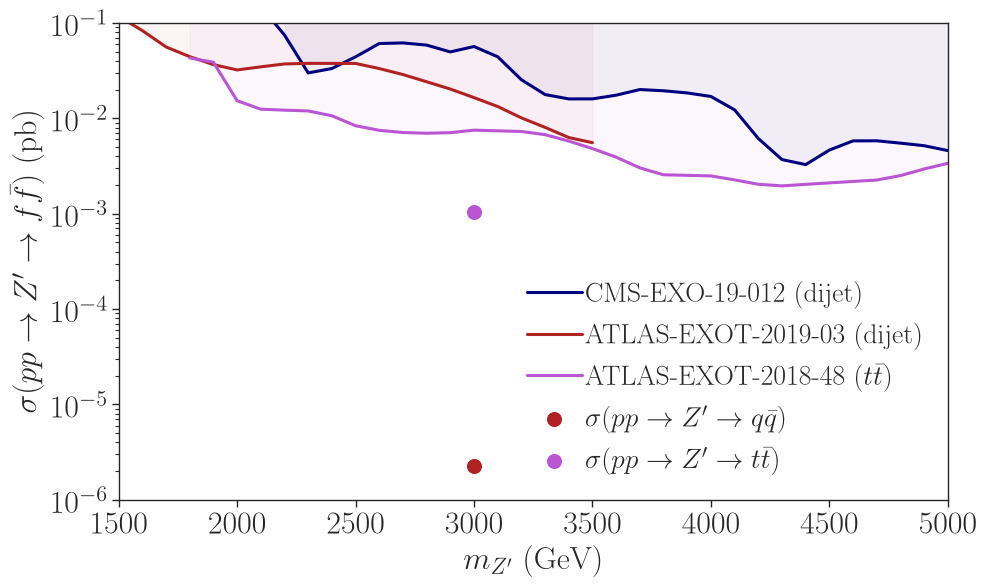

Saved plot: all_exclusions_simple_K1/direct_searches_zprime.png

Saved outputs in: /home/vinicius/EFT_ToyModel/Z_prime_constraints/all_exclusions_simple_K1


In [9]:
#!/usr/bin/env python3
"""Minimal plotting script: one figure with the three observed upper-limit curves.

Inputs:
  - rescaling_report.csv from the corrected Z' SLHA rescaling scan
  - observed_upper_limits_K1.csv from the SModelS-based limit extraction

If the upper-limit CSV is not present, the script queries the installed SModelS
3.1.1 database directly and caches the result.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================== CONFIGURATION ============================
SLHA_DIR = Path('/home/vinicius/EFT_ToyModel/processFolders/Zp_narrow_SLHAs')
REPORT_CSV = Path('/home/vinicius/EFT_ToyModel/processFolders/Zp_SLHAs_ref') / 'rescaling_report.csv'
LIMITS_CSV = Path('zprime_limits_K1/observed_upper_limits_K1.csv')
OUTPUT_DIR = Path('all_exclusions_simple_K1')
DB_PATH = 'official'
WIDTH_FRACTION = 0.01
INTERIOR_WIDTH_FRACTION = 0.0099
PLOT_MASS_MIN, PLOT_MASS_MAX = 1500, 5000
PLOT_YMIN, PLOT_YMAX = 1e-5, 0.5
SHOW_PLOTS = True
FILL_ALPHA = 0.045  # faint shading of excluded regions

# Actual MadGraph benchmark from the uploaded parameter card.
# Its LO on-shell rates are normalized with the 13 TeV SLHA report,
# rather than with the 13.6 TeV LHE integrated weight.
BENCHMARK = {
    'mass_GeV': 3000.0,
    # Explicit benchmark cross sections provided by the user
    'sigma_tt_pb': 1.048e-03,
    'sigma_jj_pb': (2.0523540e-04/9.978330e-01 * 2 * (1.083506e-03)
                    + 8.4286538e-04/9.978330e-01 * 2 * (1.083506e-03)),
}

ANALYSES = {
    'CMS-EXO-19-012': dict(tx='TRV1jj', channel='jj', final_state='dijet', color='navy'),
    'ATLAS-EXOT-2019-03': dict(tx='TRV1jj', channel='jj', final_state='dijet', color='firebrick'),
    'ATLAS-EXOT-2018-48': dict(tx='TRV1tt', channel='tt', final_state=r'$t\bar{t}$', color='mediumorchid'),
}
for aid, cfg in ANALYSES.items():
    cfg['label'] = f"{aid} ({cfg['final_state']})"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'savefig.dpi': 300, 'font.size': 11})


def load_report(path: Path) -> pd.DataFrame:
    if not path.is_file():
        raise FileNotFoundError(f'Missing rescaling report: {path}')
    df = pd.read_csv(path)
    if 'mass_GeV' not in df.columns:
        raise KeyError("rescaling_report.csv must contain a 'mass_GeV' column")
    df['mass_GeV'] = pd.to_numeric(df['mass_GeV'], errors='coerce')
    if df['mass_GeV'].isna().any():
        raise ValueError("Invalid mass_GeV values in rescaling_report.csv")
    return df


def query_limits_from_smodels(masses: np.ndarray) -> pd.DataFrame:
    from smodels.experiment.databaseObj import Database
    from smodels.base.physicsUnits import GeV, fb

    db = Database(DB_PATH)
    rows = []
    for aid, cfg in ANALYSES.items():
        results = db.getExpResults(analysisIDs=[aid])
        if len(results) != 1:
            raise RuntimeError(f'Cannot find unique SModelS result for {aid}')
        tx_matches = [tx for tx in results[0].getTxNames() if tx.txName == cfg['tx']]
        if len(tx_matches) != 1:
            raise RuntimeError(f'Cannot find unique txname {cfg["tx"]} for {aid}')
        tx = tx_matches[0]
        coords = [v[1] for _, v in sorted(tx.dataMap.items())]
        if coords != ['mass', 'totalwidth']:
            raise RuntimeError(f'Unexpected dataMap for {aid}: {tx.dataMap}')

        def get_ul(mass, width_fraction):
            coord = tx.transformPoint([float(mass) * GeV, float(mass) * width_fraction * GeV])
            val = tx.getULFor(sms=None, mass=coord)
            if val is None:
                return np.nan
            num = float(val.asNumber(fb))
            return num if np.isfinite(num) and num > 0 else np.nan

        for m in masses:
            exact = get_ul(m, WIDTH_FRACTION)
            ul = exact
            method = 'exact_1pct' if np.isfinite(exact) else 'unavailable'
            if not np.isfinite(exact) and aid.startswith('ATLAS'):
                interior = get_ul(m, INTERIOR_WIDTH_FRACTION)
                if np.isfinite(interior):
                    ul = interior
                    method = 'interior_0p99pct'
            rows.append({
                'analysis': aid,
                'mass_GeV': float(m),
                'ul_fb': ul,
                'ul_pb': ul / 1000 if np.isfinite(ul) else np.nan,
                'method': method,
            })
    return pd.DataFrame(rows)


def load_limits(path: Path, masses: np.ndarray) -> pd.DataFrame:
    if path.is_file():
        raw = pd.read_csv(path)
        print('Using existing observed upper-limit CSV:', path)
    else:
        print('Upper-limit CSV not present. Querying SModelS database and caching results.')
        raw = query_limits_from_smodels(masses)
        path.parent.mkdir(parents=True, exist_ok=True)
        raw.to_csv(path, index=False)

    required = {'analysis', 'mass_GeV', 'ul_fb'}
    missing = required - set(raw.columns)
    if missing:
        raise KeyError(f'Missing required limit CSV fields: {sorted(missing)}')

    raw = raw[raw['analysis'].isin(ANALYSES)].copy()
    raw['mass_GeV'] = pd.to_numeric(raw['mass_GeV'], errors='coerce')
    raw['ul_fb'] = pd.to_numeric(raw['ul_fb'], errors='coerce')
    raw['ul_pb'] = raw['ul_fb'] / 1000
    raw.loc[~(raw['ul_fb'] > 0), ['ul_fb', 'ul_pb']] = np.nan
    if 'method' not in raw.columns:
        raw['method'] = 'from_csv'

    if raw.duplicated(['analysis', 'mass_GeV']).any():
        raise ValueError('Duplicated limits for the same analysis/mass')

    needed = set(np.round(masses, 6))
    for aid in ANALYSES:
        present = set(np.round(raw.loc[raw['analysis'] == aid, 'mass_GeV'].dropna(), 6))
        if not needed.issubset(present):
            raise ValueError(f'Limit CSV missing some mass rows for {aid}')

    return raw.sort_values(['analysis', 'mass_GeV']).reset_index(drop=True)



def calculate_benchmark(report: pd.DataFrame) -> dict:
    """Use the explicit benchmark rates provided by the user."""
    values = dict(BENCHMARK)
    print(f"Benchmark at {values['mass_GeV']:.0f} GeV: jj = {values['sigma_jj_pb']:.6g} pb, ttbar = {values['sigma_tt_pb']:.6g} pb")
    return values

def plot_all_curves(limits: pd.DataFrame, benchmark: dict) -> Path:
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.set_yscale('log')
    ax.set_xlim(1500, 5000)
    ax.set_ylim(1e-6, 1e-1)
    ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)', fontsize=23)
    ax.set_ylabel(r'$\sigma(pp \to Z^\prime \to f\bar{f})$ (pb)', fontsize=23)
    ax.tick_params(axis='both', labelsize=23)
    ax.grid(False)

    for aid, cfg in ANALYSES.items():
        part = limits[(limits['analysis'] == aid)].sort_values('mass_GeV').copy()
        x = part['mass_GeV'].to_numpy(float)
        y = part['ul_pb'].to_numpy(float)
        ax.plot(x, y, color=cfg['color'], lw=2.2, label=cfg['label'])
        ax.fill_between(x, y, 1e-1, where=np.isfinite(y) & (y < 1e-1),
                        color=cfg['color'], alpha=FILL_ALPHA)

    # Benchmark points: use circles and the exact labels/style requested.
    ax.scatter([benchmark['mass_GeV']], [benchmark['sigma_jj_pb']],
               color=ANALYSES['ATLAS-EXOT-2019-03']['color'],
               edgecolor=ANALYSES['ATLAS-EXOT-2019-03']['color'],
               s=100, marker='o', zorder=4,
               label=r'$\sigma(p p \to Z^\prime \to q\bar{q})$')
    ax.scatter([benchmark['mass_GeV']], [benchmark['sigma_tt_pb']],
               color=ANALYSES['ATLAS-EXOT-2018-48']['color'],
               edgecolor=ANALYSES['ATLAS-EXOT-2018-48']['color'],
               s=100, marker='o', zorder=4,
               label=r'$\sigma(p p \to Z^\prime \to t\bar{t})$')

    ax.legend(loc='lower right', fontsize=20, framealpha=0, ncols=1, handletextpad=0.1)
    fig.tight_layout()

    out_png = OUTPUT_DIR / 'direct_searches_zprime.png'
    out_pdf = out_png.with_suffix('.pdf')
    fig.savefig(out_png, dpi=300, bbox_inches='tight')
    fig.savefig(out_pdf, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    print('Saved plot:', out_png)
    return out_png


def main():
    print('Loading corrected SLHA rescaling report:', REPORT_CSV)
    report = load_report(REPORT_CSV)
    masses = np.sort(report['mass_GeV'].unique())
    limits = load_limits(LIMITS_CSV, masses)
    print('Upper-limit retrieval summary:')
    print(limits.groupby(['analysis', 'method'], dropna=False).size().to_string())
    benchmark = calculate_benchmark(report)
    plot_all_curves(limits, benchmark)
    limits.to_csv(OUTPUT_DIR / 'separate_observed_upper_limits_K1.csv', index=False)
    print('\nSaved outputs in:', OUTPUT_DIR.resolve())


if __name__ == '__main__':
    main()
